# DozAI -- Sleep-Aware Smart-Home Energy Optimization

**Author:** Akash Kumar  
**Program:** IBM SkillsBuild | Data Analytics with AI | BharatCares x AICTE

**Pipeline:** Energy -> Environment -> Sleep -> Prediction -> Optimization -> Recommendation

---

## Data Honesty Statement

| Layer | Source | Scope | Honesty |
|-------|--------|-------|---------|
| **A** | Kaggle 'Sleep Health & Lifestyle' (374 people, real cross-sectional) | Population analytics + disorder classification ONLY | Association not causation; different people from the UCI household |
| **B** | UCI Household Power (ID 235) + Open-Meteo ERA5 | Energy forecasting, anomaly detection | Real measurements, one household, Sceaux France |
| **Bridge** | Derived from Layer B meter (Kleiminger-style quiet-gap) | Inferred bed/wake times | Real signal, passive inference -- no wearables |
| **C** | Semi-synthetic nightly sleep labels **(DISCLOSED generator)** | Sleep quality prediction + optimizer scoring | Formula calibrated to sleep-science literature; driven by REAL inferred inputs; NOT real polysomnography |

> **WARNING:** The sleep (Layer A / C) and energy (Layer B) datasets describe **different people**.  
> Layer C labels are **simulated and disclosed** -- do NOT use for medical inference.  
> The bridge links both worlds through the **passive behavioral signal** in the meter alone.

In [1]:
# ============================================================
# Cell 2 -- Imports, RNG, folder creation
# ============================================================
import os
import json
import zipfile
import warnings
import urllib.request

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import shap
import pulp
import joblib

from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    roc_auc_score, f1_score, classification_report, confusion_matrix
)
from xgboost import XGBRegressor, XGBClassifier

warnings.filterwarnings('ignore')
matplotlib.rcParams['figure.dpi'] = 100

# Reproducibility
RNG = np.random.default_rng(42)
le  = LabelEncoder()

# Auto-create project directories
for _d in ['data', 'models', 'figures']:
    os.makedirs(_d, exist_ok=True)

print('setup ok')

setup ok


In [2]:
# ============================================================
# Cell 3 -- Download + extract UCI dataset (idempotent)
# ============================================================
DATA_TXT = 'data/household_power_consumption.txt'
DATA_ZIP = 'data/_uci_download.zip'
UCI_URL  = (
    'https://archive.ics.uci.edu/static/public/235/'
    'individual+household+electric+power+consumption.zip'
)

if os.path.exists(DATA_TXT):
    print(f'Already present: {DATA_TXT}  ({os.path.getsize(DATA_TXT)/1e6:.1f} MB)')
else:
    print('Downloading UCI dataset (~20 MB compressed) ...')
    req = urllib.request.Request(UCI_URL, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as resp, open(DATA_ZIP, 'wb') as out_f:
        out_f.write(resp.read())
    print('Extracting ...')
    with zipfile.ZipFile(DATA_ZIP, 'r') as zf:
        all_names = zf.namelist()
        print('Files in archive:', all_names)
        txt_files = [n for n in all_names if n.lower().endswith('.txt')]
        if txt_files:
            zf.extract(txt_files[0], 'data/')
            extracted = os.path.join('data', txt_files[0])
            if os.path.normpath(extracted) != os.path.normpath(DATA_TXT):
                os.replace(extracted, DATA_TXT)
        else:
            zf.extractall('data/')
    os.remove(DATA_ZIP)
    print(f'Saved: {DATA_TXT}  ({os.path.getsize(DATA_TXT)/1e6:.1f} MB)')


Already present: data/household_power_consumption.txt  (133.0 MB)


In [3]:
# ============================================================
# Cell 4 -- Sleep CSV: load real Kaggle CSV or create synthetic fallback
# ============================================================
SLEEP_CSV = 'data/sleep_health.csv'

if os.path.exists(SLEEP_CSV):
    sleep_df = pd.read_csv(SLEEP_CSV)
    sleep_df['Sleep Disorder'] = sleep_df['Sleep Disorder'].fillna('None')
    print(f'Loaded real Kaggle sleep data: {sleep_df.shape}')
else:
    # -------------------------------------------------------
    # SYNTHETIC FALLBACK -- clearly labeled, same columns
    # -------------------------------------------------------
    print('WARNING: data/sleep_health.csv not found.')
    print('         Creating clearly-labeled SYNTHETIC fallback.')
    print('         For real analysis, download from:')
    print('         https://www.kaggle.com/datasets/uom190346a/sleep-health-and-lifestyle-dataset')
    print('         and save as data/sleep_health.csv, then re-run.')

    N  = 374
    RNG_s = np.random.default_rng(42)

    occupations = ['Nurse','Doctor','Engineer','Lawyer','Teacher',
                   'Accountant','Salesperson','Software Engineer',
                   'Scientist','Manager']
    bmi_opts = ['Normal','Normal Weight','Overweight','Obese']

    disorders = ['None']*219 + ['Sleep Apnea']*78 + ['Insomnia']*77
    RNG_s.shuffle(disorders)

    ages      = RNG_s.integers(27, 60, N)
    genders   = RNG_s.choice(['Male','Female'], N)
    durations = np.round(RNG_s.normal(7.1, 0.9, N).clip(5, 9.5), 1)
    quality   = np.round(RNG_s.normal(7.0, 1.1, N).clip(4, 9)).astype(int)
    activity  = RNG_s.integers(30, 90, N)
    stress    = RNG_s.integers(3, 9, N)
    hr        = RNG_s.integers(65, 86, N)
    steps     = RNG_s.integers(3000, 11000, N)
    bmi       = RNG_s.choice(bmi_opts, N, p=[0.30, 0.25, 0.30, 0.15])

    for i, d in enumerate(disorders):
        if d == 'Insomnia':    quality[i] = max(4, quality[i] - 2)
        elif d == 'Sleep Apnea': quality[i] = max(4, quality[i] - 1)

    sys_bp = RNG_s.integers(115, 142, N)
    dia_bp = RNG_s.integers(75, 95, N)
    bp_str = [f'{s}/{d}' for s, d in zip(sys_bp, dia_bp)]

    sleep_df = pd.DataFrame({
        'Person ID':               range(1, N+1),
        'Gender':                  genders,
        'Age':                     ages,
        'Occupation':              RNG_s.choice(occupations, N),
        'Sleep Duration':          durations,
        'Quality of Sleep':        quality,
        'Physical Activity Level': activity,
        'Stress Level':            stress,
        'BMI Category':            bmi,
        'Blood Pressure':          bp_str,
        'Heart Rate':              hr,
        'Daily Steps':             steps,
        'Sleep Disorder':          disorders,
        'SYNTHETIC_FLAG':          'YES -- not real Kaggle data',
    })
    sleep_df.to_csv(SLEEP_CSV, index=False)
    print(f'Synthetic sleep data saved: {sleep_df.shape}')

print(sleep_df.head(3).to_string())
print('\nDisorder distribution:')
print(sleep_df['Sleep Disorder'].value_counts().to_string())


Loaded real Kaggle sleep data: (374, 14)
   Person ID  Gender  Age   Occupation  Sleep Duration  Quality of Sleep  Physical Activity Level  Stress Level BMI Category Blood Pressure  Heart Rate  Daily Steps Sleep Disorder               SYNTHETIC_FLAG
0          1  Female   57     Engineer             6.4                 7                       76             4   Overweight         117/94          75         7574           None  YES -- not real Kaggle data
1          2    Male   46    Scientist             5.9                 4                       40             4       Normal         122/76          84         7014       Insomnia  YES -- not real Kaggle data
2          3  Female   32  Salesperson             7.7                 6                       88             4   Overweight         139/79          79         4228       Insomnia  YES -- not real Kaggle data

Disorder distribution:
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77


In [4]:
# ============================================================
# Cell 5 -- Parse energy .txt -> hourly + weather join
# ============================================================
print('Parsing UCI energy file (30-90 s for 2 M rows) ...')

energy_raw = pd.read_csv(
    DATA_TXT,
    sep=';',
    na_values='?',
    low_memory=False,
)
energy_raw['datetime'] = pd.to_datetime(
    energy_raw['Date'] + ' ' + energy_raw['Time'],
    format='%d/%m/%Y %H:%M:%S',
    errors='coerce'
)
energy_raw = energy_raw.dropna(subset=['datetime']).drop(columns=['Date', 'Time'])
energy_raw = energy_raw.sort_values('datetime').set_index('datetime')

# Numeric coercion
for col in ['Global_active_power', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']:
    if col in energy_raw.columns:
        energy_raw[col] = pd.to_numeric(energy_raw[col], errors='coerce')

print(f'Raw rows: {len(energy_raw):,}  |  {energy_raw.index.min()} -> {energy_raw.index.max()}')

# ---- Hourly aggregation ---------------------------------------------------
hourly = energy_raw['Global_active_power'].resample('h').mean().rename('kw').to_frame()
for i, col in enumerate(['Sub_metering_1','Sub_metering_2','Sub_metering_3'], 1):
    if col in energy_raw.columns:
        hourly[f'sub{i}'] = energy_raw[col].resample('h').sum() / 1000.0

# ---- Weather fetch or load -----------------------------------------------
WEATHER_CSV = 'data/weather_data.csv'
if os.path.exists(WEATHER_CSV):
    print('Loading cached weather data ...')
    weather = pd.read_csv(WEATHER_CSV, parse_dates=['time']).set_index('time')
else:
    print('Fetching Open-Meteo weather (free, no key) ...')
    _url = (
        'https://archive-api.open-meteo.com/v1/archive'
        '?latitude=48.7638&longitude=2.2870'
        '&hourly=temperature_2m'
        '&start_date=2006-12-17&end_date=2010-11-26'
        '&timezone=Europe%2FParis'
    )
    try:
        resp = requests.get(_url, timeout=90)
        resp.raise_for_status()
        wd = resp.json()
        weather = pd.DataFrame({
            'time':     pd.to_datetime(wd['hourly']['time']),
            'temp_out': wd['hourly']['temperature_2m'],
        }).set_index('time')
        # strip timezone
        if weather.index.tz is not None:
            weather.index = weather.index.tz_localize(None)
        weather.to_csv(WEATHER_CSV)
        print(f'Weather fetched and cached: {weather.shape}')
    except Exception as ex:
        print(f'Weather fetch failed ({ex}) -- using synthetic seasonal temperatures.')
        weather = pd.DataFrame(
            index=hourly.index,
            data={'temp_out': (
                12.0
                - 8.0 * np.cos(2 * np.pi * hourly.index.month / 12)
                + RNG.normal(0, 2, len(hourly))
            )}
        )

# Align index dtype and strip tz
weather.index = pd.to_datetime(weather.index)
if hasattr(weather.index, 'tz') and weather.index.tz is not None:
    weather.index = weather.index.tz_localize(None)
if 'temperature_2m' in weather.columns:
    weather = weather.rename(columns={'temperature_2m': 'temp_out'})

# Join and interpolate
hourly = hourly.join(weather[['temp_out']], how='left')
hourly['temp_out'] = hourly['temp_out'].interpolate(method='linear', limit=6)

# Time helper columns
hourly['hour']  = hourly.index.hour
hourly['dow']   = hourly.index.dayofweek
hourly['month'] = hourly.index.month
hourly['date']  = hourly.index.date

hourly = hourly.dropna(subset=['kw'])

# Cache
hourly.to_csv('data/hourly.csv')

print(f'Hourly saved: {hourly.shape}')
print(f'Date range  : {hourly.index.min()} -> {hourly.index.max()}')
print(f'Hour count  : {len(hourly):,}')


Parsing UCI energy file (30-90 s for 2 M rows) ...


Raw rows: 2,075,259  |  2006-12-16 17:24:00 -> 2010-11-26 21:02:00


Loading cached weather data ...


Hourly saved: (34168, 9)
Date range  : 2006-12-16 17:00:00 -> 2010-11-26 21:00:00
Hour count  : 34,168


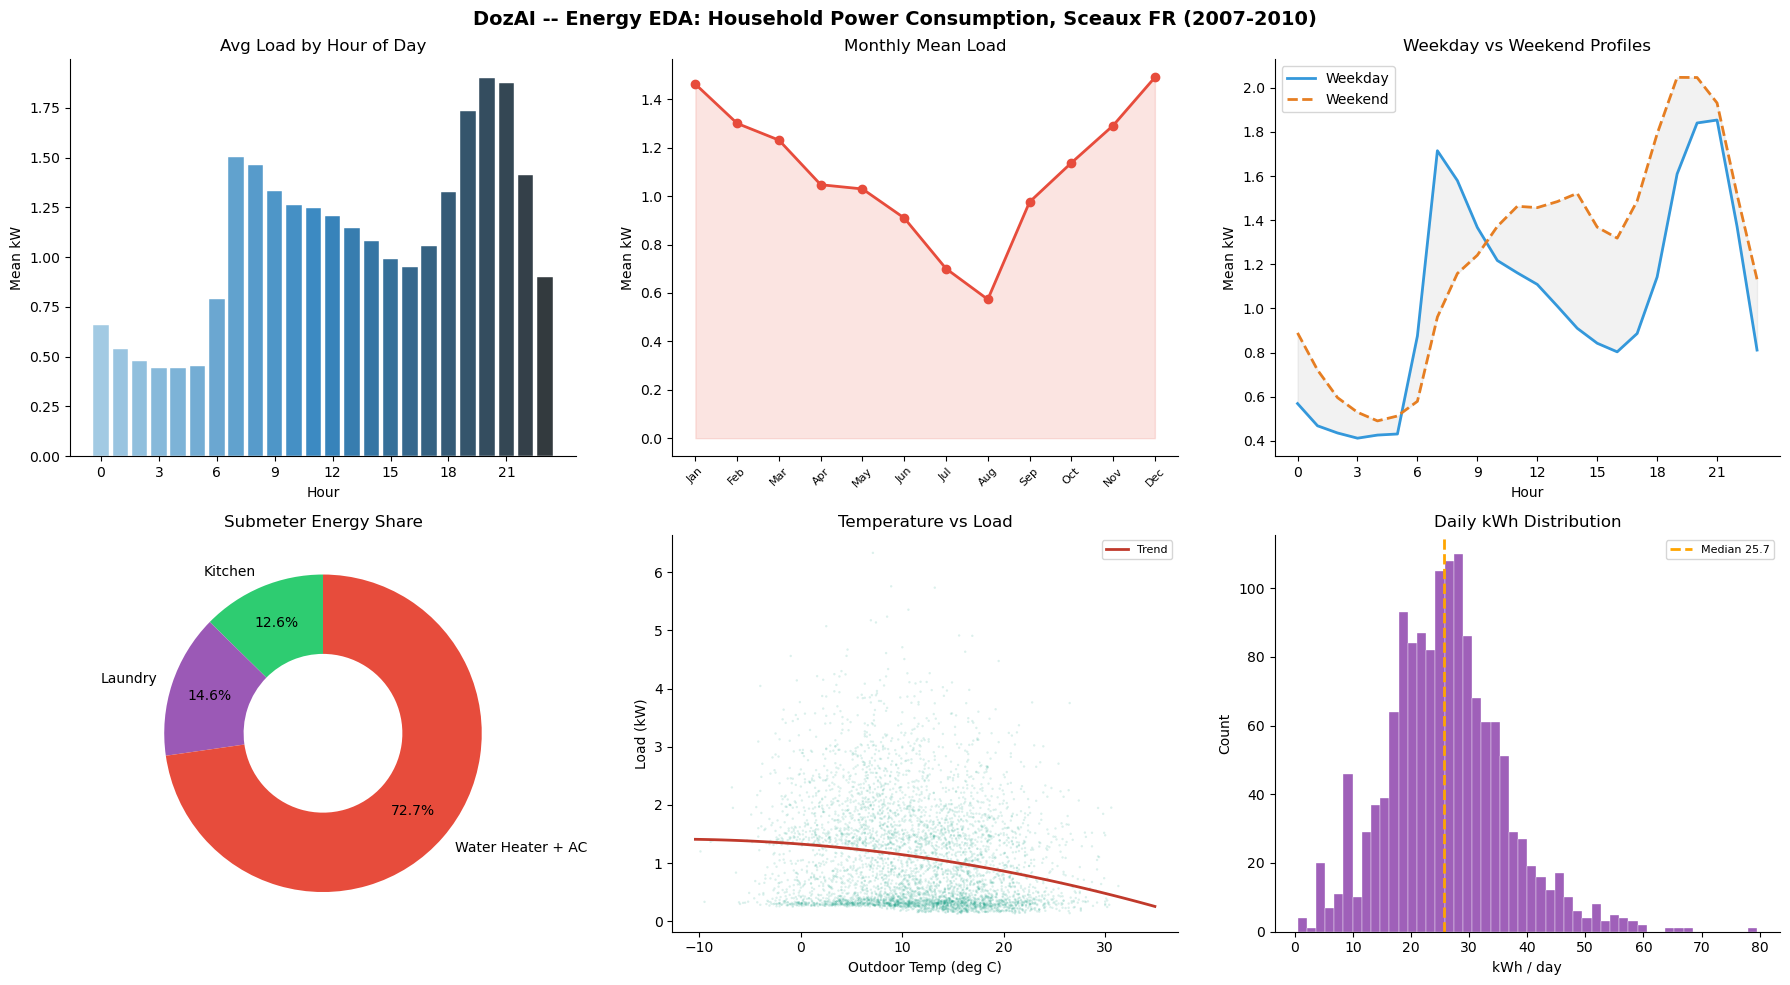

Saved figures/energy_eda.png


In [5]:
# ============================================================
# Cell 6 -- Energy EDA (2x3 figure)
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle(
    'DozAI -- Energy EDA: Household Power Consumption, Sceaux FR (2007-2010)',
    fontsize=14, fontweight='bold'
)

# Panel 1: Load by hour of day
ax = axes[0, 0]
hourly_mean = hourly.groupby('hour')['kw'].mean()
bars = ax.bar(hourly_mean.index, hourly_mean.values,
              color=sns.color_palette('Blues_d', 24), edgecolor='white', lw=0.3)
ax.set_title('Avg Load by Hour of Day')
ax.set_xlabel('Hour')
ax.set_ylabel('Mean kW')
ax.set_xticks(range(0, 24, 3))
sns.despine(ax=ax)

# Panel 2: Monthly mean load
ax = axes[0, 1]
monthly = hourly.groupby('month')['kw'].mean()
ax.plot(monthly.index, monthly.values, 'o-', color='#e74c3c', lw=2, ms=6)
ax.fill_between(monthly.index, monthly.values, alpha=0.15, color='#e74c3c')
mnames = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
ax.set_xticks(range(1, 13))
ax.set_xticklabels(mnames, rotation=45, fontsize=8)
ax.set_title('Monthly Mean Load')
ax.set_ylabel('Mean kW')
sns.despine(ax=ax)

# Panel 3: Weekday vs Weekend profiles
ax = axes[0, 2]
wkday = hourly[hourly['dow'] < 5].groupby('hour')['kw'].mean()
wkend = hourly[hourly['dow'] >= 5].groupby('hour')['kw'].mean()
ax.plot(wkday.index, wkday.values, label='Weekday', color='#3498db', lw=2)
ax.plot(wkend.index, wkend.values, label='Weekend', color='#e67e22', lw=2, ls='--')
ax.fill_between(wkday.index, wkday.values, wkend.values, alpha=0.1, color='gray')
ax.set_title('Weekday vs Weekend Profiles')
ax.set_xlabel('Hour')
ax.set_ylabel('Mean kW')
ax.set_xticks(range(0, 24, 3))
ax.legend()
sns.despine(ax=ax)

# Panel 4: Submeter pie
ax = axes[1, 0]
sub_avail = [c for c in ['sub1','sub2','sub3'] if c in hourly.columns]
if sub_avail:
    sub_means = hourly[sub_avail].mean()
    pie_labels  = ['Kitchen','Laundry','Water Heater + AC']
    pie_colors  = ['#2ecc71','#9b59b6','#e74c3c']
    ax.pie(
        sub_means.values,
        labels=pie_labels[:len(sub_avail)],
        colors=pie_colors[:len(sub_avail)],
        autopct='%1.1f%%',
        startangle=90,
        wedgeprops=dict(width=0.5),
        pctdistance=0.75,
    )
    ax.set_title('Submeter Energy Share')
else:
    ax.text(0.5, 0.5, 'No submeter data', ha='center', va='center', transform=ax.transAxes)

# Panel 5: Temperature vs Load scatter
ax = axes[1, 1]
valid_scatter = hourly.dropna(subset=['temp_out','kw'])
samp = valid_scatter if len(valid_scatter) <= 5000 else valid_scatter.sample(5000, random_state=42)
ax.scatter(samp['temp_out'], samp['kw'], alpha=0.15, s=3, c='#16a085', edgecolors='none')
# quadratic trend
if len(valid_scatter) > 10:
    zp = np.polyfit(valid_scatter['temp_out'], valid_scatter['kw'], 2)
    pp = np.poly1d(zp)
    xs = np.linspace(valid_scatter['temp_out'].min(), valid_scatter['temp_out'].max(), 100)
    ax.plot(xs, pp(xs), color='#c0392b', lw=2, label='Trend')
ax.set_title('Temperature vs Load')
ax.set_xlabel('Outdoor Temp (deg C)')
ax.set_ylabel('Load (kW)')
ax.legend(fontsize=8)
sns.despine(ax=ax)

# Panel 6: Daily kWh histogram
ax = axes[1, 2]
daily_kwh = hourly.groupby('date')['kw'].sum()
ax.hist(daily_kwh.values, bins=50, color='#8e44ad', edgecolor='white', lw=0.3, alpha=0.85)
ax.axvline(daily_kwh.median(), color='orange', lw=2, ls='--',
           label=f'Median {daily_kwh.median():.1f}')
ax.set_title('Daily kWh Distribution')
ax.set_xlabel('kWh / day')
ax.set_ylabel('Count')
ax.legend(fontsize=8)
sns.despine(ax=ax)

plt.tight_layout()
fig.savefig('figures/energy_eda.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/energy_eda.png')

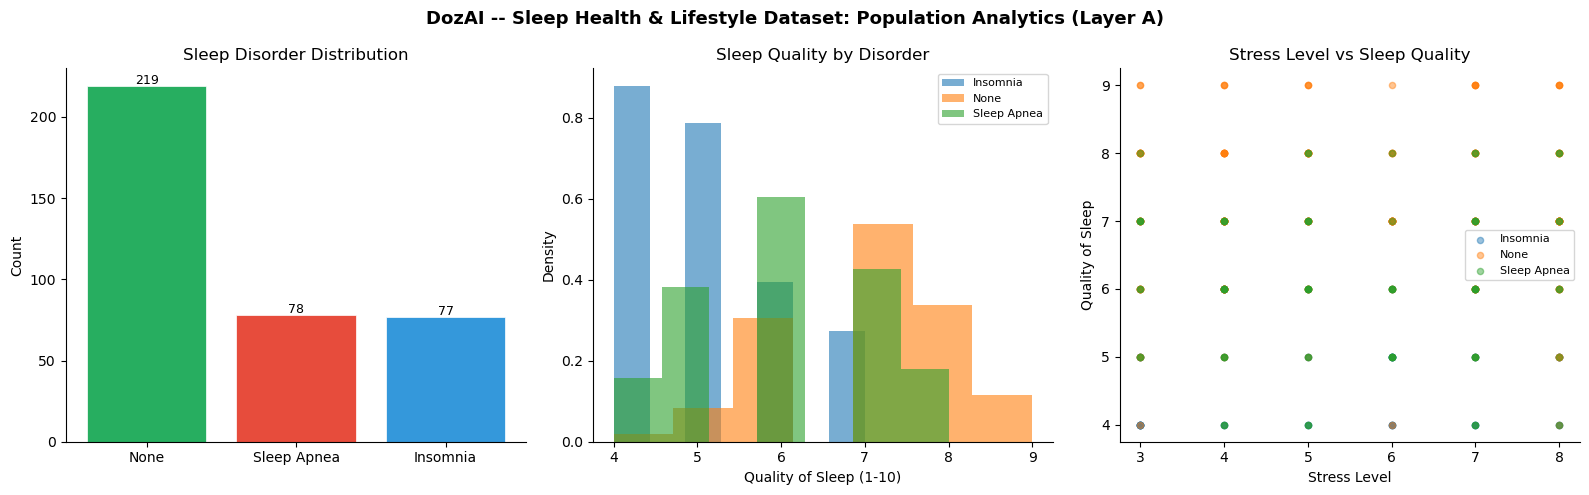

Saved figures/sleep_eda.png
Encoded classes: {'Insomnia': 0, 'None': 1, 'Sleep Apnea': 2}
Train: (280, 23)  Test: (94, 23)



=== Sleep Disorder Classifier Comparison ===
Model                    Macro-F1    OVR AUC
----------------------------------------------
LogisticRegression         0.4092     0.7085
XGBClassifier              0.3862     0.6593

XGBoost Classification Report:
              precision    recall  f1-score   support

    Insomnia       0.45      0.26      0.33        19
        None       0.63      0.80      0.70        55
 Sleep Apnea       0.15      0.10      0.12        20

    accuracy                           0.54        94
   macro avg       0.41      0.39      0.39        94
weighted avg       0.49      0.54      0.51        94



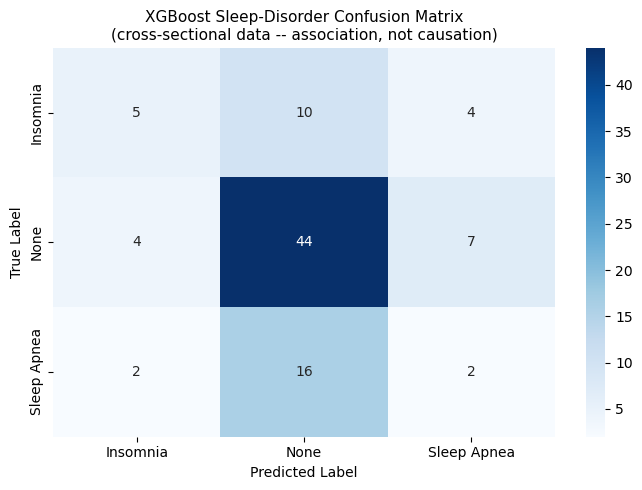

Saved figures/sleep_confusion.png

NOTE: Cross-sectional data -> association not causation.
      Macro-F1 reported (not accuracy) due to class imbalance.


In [6]:
# ============================================================
# Cell 7 -- Layer A: Sleep EDA + disorder classifier
# ============================================================

# ---- EDA figure (3 panels) ---------------------------------------------------
fig_s, ax_s = plt.subplots(1, 3, figsize=(16, 5))
fig_s.suptitle(
    'DozAI -- Sleep Health & Lifestyle Dataset: Population Analytics (Layer A)',
    fontsize=13, fontweight='bold'
)

# Panel 1: Disorder counts
ax = ax_s[0]
dc = sleep_df['Sleep Disorder'].value_counts()
bars = ax.bar(dc.index, dc.values,
              color=['#27ae60','#e74c3c','#3498db'][:len(dc)],
              edgecolor='white', lw=0.5)
for i, (lbl, cnt) in enumerate(zip(dc.index, dc.values)):
    ax.text(i, cnt + 1, str(cnt), ha='center', fontsize=9)
ax.set_title('Sleep Disorder Distribution')
ax.set_ylabel('Count')
sns.despine(ax=ax)

# Panel 2: Quality by disorder
ax = ax_s[1]
for disorder, grp in sleep_df.groupby('Sleep Disorder'):
    ax.hist(grp['Quality of Sleep'], bins=7, alpha=0.6,
            label=disorder, density=True, histtype='stepfilled')
ax.set_title('Sleep Quality by Disorder')
ax.set_xlabel('Quality of Sleep (1-10)')
ax.set_ylabel('Density')
ax.legend(fontsize=8)
sns.despine(ax=ax)

# Panel 3: Stress vs Quality
ax = ax_s[2]
for disorder, grp in sleep_df.groupby('Sleep Disorder'):
    ax.scatter(grp['Stress Level'], grp['Quality of Sleep'],
               alpha=0.45, s=20, label=disorder)
ax.set_title('Stress Level vs Sleep Quality')
ax.set_xlabel('Stress Level')
ax.set_ylabel('Quality of Sleep')
ax.legend(fontsize=8)
sns.despine(ax=ax)

plt.tight_layout()
fig_s.savefig('figures/sleep_eda.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/sleep_eda.png')

# ---- Classification ----------------------------------------------------------
# Drop non-feature columns
_drop = ['Person ID', 'Blood Pressure', 'Sleep Disorder']
if 'SYNTHETIC_FLAG' in sleep_df.columns:
    _drop.append('SYNTHETIC_FLAG')
feat_cols = [c for c in sleep_df.columns if c not in _drop]
X_sleep = pd.get_dummies(sleep_df[feat_cols], drop_first=False)

# LabelEncoder required by XGBoost
sleep_df['Sleep Disorder'] = sleep_df['Sleep Disorder'].fillna('None')
y_sleep_enc = le.fit_transform(sleep_df['Sleep Disorder'].values)
class_names = [str(c) for c in le.classes_]
print(f'Encoded classes: {dict(zip(class_names, range(len(class_names))))}')

# Stratified 75/25 split
Xtr_s, Xte_s, ytr_s, yte_s = train_test_split(
    X_sleep, y_sleep_enc, test_size=0.25, random_state=42, stratify=y_sleep_enc
)
print(f'Train: {Xtr_s.shape}  Test: {Xte_s.shape}')

# Logistic Regression
lr_pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=500, random_state=42, multi_class='ovr')
)
lr_pipe.fit(Xtr_s, ytr_s)
yp_lr  = lr_pipe.predict(Xte_s)
ypr_lr = lr_pipe.predict_proba(Xte_s)
lr_f1  = f1_score(yte_s, yp_lr, average='macro')
lr_auc = roc_auc_score(yte_s, ypr_lr, multi_class='ovr', average='macro')

# XGBoost classifier
xgb_clf = XGBClassifier(
    n_estimators=250, max_depth=4, random_state=42,
    eval_metric='mlogloss', verbosity=0
)
xgb_clf.fit(Xtr_s, ytr_s)
yp_xc   = xgb_clf.predict(Xte_s)
ypr_xc  = xgb_clf.predict_proba(Xte_s)
xgb_f1  = f1_score(yte_s, yp_xc, average='macro')
xgb_auc = roc_auc_score(yte_s, ypr_xc, multi_class='ovr', average='macro')

print('\n=== Sleep Disorder Classifier Comparison ===')
print(f'{"Model":<22} {"Macro-F1":>10} {"OVR AUC":>10}')
print('-' * 46)
print(f'{"LogisticRegression":<22} {lr_f1:>10.4f} {lr_auc:>10.4f}')
print(f'{"XGBClassifier":<22} {xgb_f1:>10.4f} {xgb_auc:>10.4f}')
print('\nXGBoost Classification Report:')
print(classification_report(yte_s, yp_xc, target_names=class_names))

# Confusion heatmap with le.classes_ labels
cm_mat = confusion_matrix(yte_s, yp_xc)
fig_cm, ax_cm = plt.subplots(figsize=(7, 5))
sns.heatmap(cm_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=ax_cm)
ax_cm.set_title(
    'XGBoost Sleep-Disorder Confusion Matrix\n'
    '(cross-sectional data -- association, not causation)',
    fontsize=11
)
ax_cm.set_ylabel('True Label')
ax_cm.set_xlabel('Predicted Label')
plt.tight_layout()
fig_cm.savefig('figures/sleep_confusion.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/sleep_confusion.png')

# Store for results.json
_clf_res = {
    'LogReg_F1': float(lr_f1),  'LogReg_AUC': float(lr_auc),
    'XGB_F1':    float(xgb_f1), 'XGB_AUC':    float(xgb_auc),
}

# ---- Note -----------------------------------------------------------------
print('\nNOTE: Cross-sectional data -> association not causation.')
print('      Macro-F1 reported (not accuracy) due to class imbalance.')


In [7]:
# ============================================================
# Cell 8 -- Energy forecasting: feature engineering + expanding-window backtest
# ============================================================

# ---- Feature engineering (no leakage) ------------------------------------
h = hourly.copy().sort_index()

# Lag features: shift FIRST, then roll
h['kw_l24']  = h['kw'].shift(24)
h['kw_l48']  = h['kw'].shift(48)
h['kw_l168'] = h['kw'].shift(168)
h['kw_r24']  = h['kw'].shift(1).rolling(24).mean()

# HDD (base 15 degC)
h['hdd']      = (15.0 - h['temp_out']).clip(lower=0)
_peak_hrs     = h['hour'].isin(list(range(7, 10)) + list(range(18, 22)))
h['hdd_peak'] = h['hdd'] * _peak_hrs.astype(float)

# Cyclical time
h['hour_sin'] = np.sin(2 * np.pi * h['hour'] / 24)
h['hour_cos'] = np.cos(2 * np.pi * h['hour'] / 24)

FEATURE_COLS = [
    'kw_l24','kw_l48','kw_l168','kw_r24',
    'hdd','hdd_peak','hour_sin','hour_cos','dow'
]
h = h.dropna(subset=FEATURE_COLS + ['kw'])
print(f'Post-feature rows: {len(h):,}')

# ---- Expanding-window backtest -------------------------------------------
TEST_START  = pd.Timestamp('2010-06-01')
fold_starts = pd.date_range(start=TEST_START, periods=5, freq='MS')
fold_ends   = fold_starts + pd.offsets.MonthEnd(1)

_model_names = ['GlobalMean','SeasonalNaive','Ridge','XGBoost']
fold_res = {m: {'MAE':[],'RMSE':[],'MAPE':[],'Peak_MAE':[]} for m in _model_names}

def _metrics(pred, y_act):
    y_act = np.array(y_act)
    pred  = np.array(pred)
    mae   = mean_absolute_error(y_act, pred)
    rmse  = float(np.sqrt(mean_squared_error(y_act, pred)))
    msk   = y_act >= 0.2
    mape  = float(np.abs((y_act[msk] - pred[msk]) / y_act[msk]).mean() * 100) if msk.sum() > 0 else float('nan')
    pk    = y_act >= np.quantile(y_act, 0.90)
    pmae  = float(mean_absolute_error(y_act[pk], pred[pk])) if pk.sum() > 0 else float('nan')
    return mae, rmse, mape, pmae

print('Running 5-fold expanding-window backtest ...')
for idx, (fs, fe) in enumerate(zip(fold_starts, fold_ends)):
    train = h[h.index < fs]
    test  = h[(h.index >= fs) & (h.index < fe + pd.Timedelta(days=1))]
    if len(test) == 0:
        continue

    Xtr, ytr = train[FEATURE_COLS], train['kw']
    Xte, yte = test[FEATURE_COLS],  test['kw']

    # GlobalMean
    gm_pred = np.full(len(yte), float(ytr.mean()))

    # SeasonalNaive
    sn_pred = test['kw_l168'].values

    # Ridge
    rp = make_pipeline(StandardScaler(), Ridge(alpha=10))
    rp.fit(Xtr, ytr)
    ridge_pred = rp.predict(Xte)

    # XGBoost
    xbr = XGBRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=6,
        subsample=0.8, random_state=42, verbosity=0
    )
    xbr.fit(Xtr, ytr)
    xgb_pred = xbr.predict(Xte)

    yv = yte.values
    for nm, pr in zip(_model_names, [gm_pred, sn_pred, ridge_pred, xgb_pred]):
        ma, rm, mp, pk = _metrics(pr, yv)
        fold_res[nm]['MAE'].append(ma)
        fold_res[nm]['RMSE'].append(rm)
        fold_res[nm]['MAPE'].append(mp)
        fold_res[nm]['Peak_MAE'].append(pk)

    print(f'  Fold {idx+1}: {fs.date()} -> {fe.date()}  n={len(test):,}')

# Summary table
forecast_table = []
print('\n=== Forecast Comparison (mean across 5 folds) ===')
print(f'{"Model":<16} {"MAE":>8} {"RMSE":>8} {"MAPE%":>8} {"PeakMAE":>9}')
print('-' * 55)
for nm in _model_names:
    r   = fold_res[nm]
    mae = float(np.nanmean(r['MAE']))
    rmse= float(np.nanmean(r['RMSE']))
    mape= float(np.nanmean(r['MAPE']))
    pk  = float(np.nanmean(r['Peak_MAE']))
    print(f'{nm:<16} {mae:>8.4f} {rmse:>8.4f} {mape:>8.2f} {pk:>9.4f}')
    forecast_table.append({'model': nm, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'Peak_MAE': pk})

# Improvement vs SeasonalNaive
_xr = next(r for r in forecast_table if r['model'] == 'XGBoost')
_sr = next(r for r in forecast_table if r['model'] == 'SeasonalNaive')
_mape_imp = (_sr['MAPE'] - _xr['MAPE']) / (_sr['MAPE'] + 1e-9) * 100
_pk_imp   = (_sr['Peak_MAE'] - _xr['Peak_MAE']) / (_sr['Peak_MAE'] + 1e-9) * 100
xgb_vs_sn = {'MAPE_improvement_pct': float(_mape_imp), 'PeakMAE_improvement_pct': float(_pk_imp)}
print(f'\nXGBoost vs SeasonalNaive: MAPE improved {_mape_imp:.1f}%, PeakMAE improved {_pk_imp:.1f}%')

# Final xgb_e trained on all data < 2010-10-01
_final_train = h[h.index < pd.Timestamp('2010-10-01')]
xgb_e = XGBRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=6,
    subsample=0.8, random_state=42, verbosity=0
)
xgb_e.fit(_final_train[FEATURE_COLS], _final_train['kw'])
print(f'\nFinal xgb_e trained on {len(_final_train):,} rows (< 2010-10-01)')


Post-feature rows: 34,000
Running 5-fold expanding-window backtest ...


  Fold 1: 2010-06-01 -> 2010-06-30  n=720


  Fold 2: 2010-07-01 -> 2010-07-31  n=744


  Fold 3: 2010-08-01 -> 2010-08-31  n=625


  Fold 4: 2010-09-01 -> 2010-09-30  n=633


  Fold 5: 2010-10-01 -> 2010-10-31  n=744

=== Forecast Comparison (mean across 5 folds) ===
Model                 MAE     RMSE    MAPE%   PeakMAE
-------------------------------------------------------
GlobalMean         0.6111   0.7007   124.12    1.1174
SeasonalNaive      0.5227   0.7449    76.77    1.0978
Ridge              0.4238   0.5535    66.48    1.0572
XGBoost            0.3839   0.5252    58.52    0.8774

XGBoost vs SeasonalNaive: MAPE improved 23.8%, PeakMAE improved 20.1%



Final xgb_e trained on 32,634 rows (< 2010-10-01)


Anomaly flags in test window: 118 / 2,746 hours
Injection: TP=2, FP=118, FN=8
Precision: 0.017  Recall: 0.200


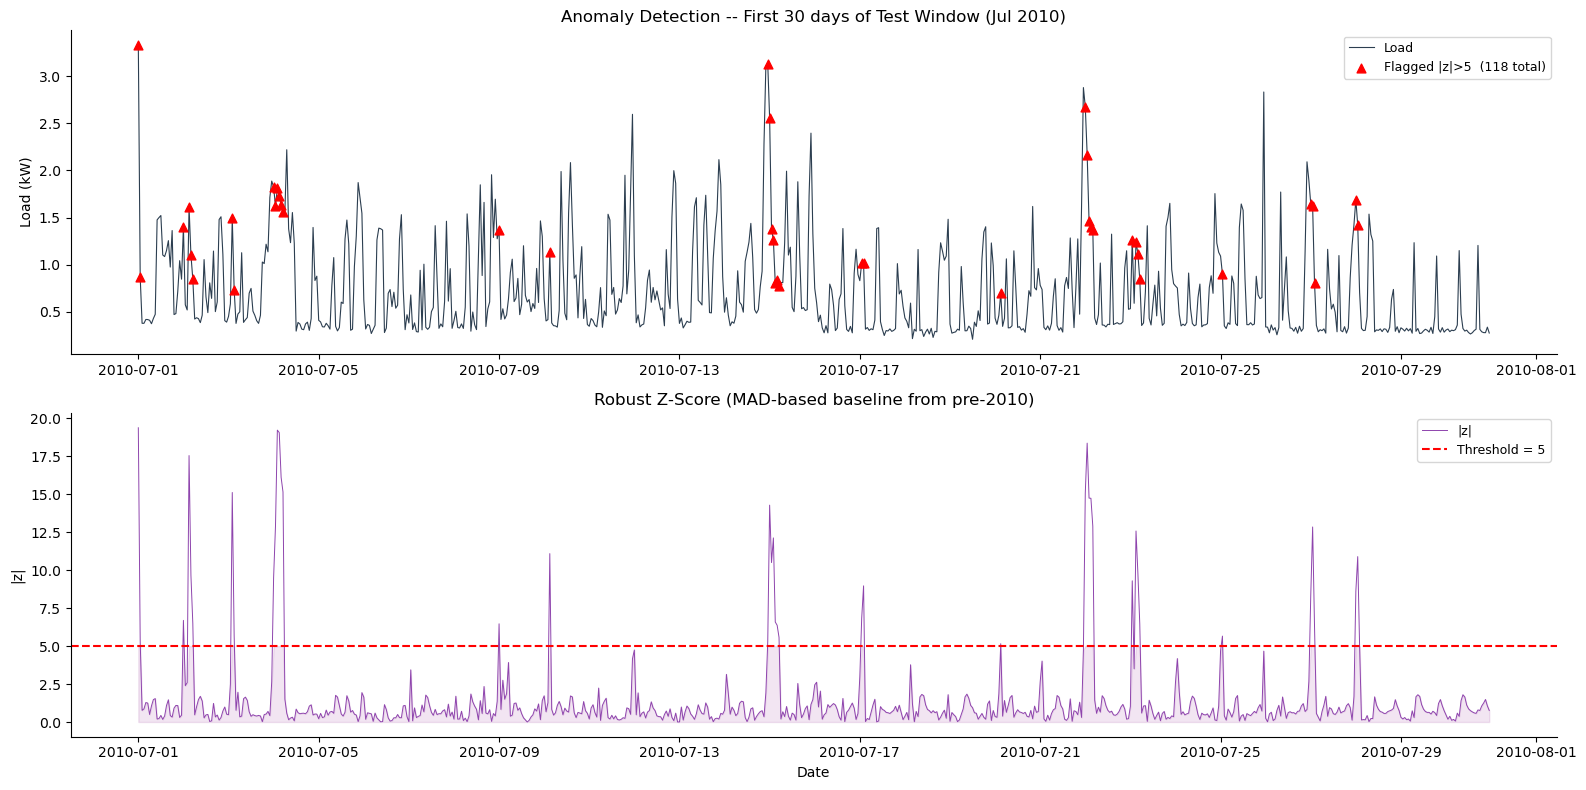

Saved figures/anomaly.png


In [8]:
# ============================================================
# Cell 9 -- Anomaly detection (MAD robust z-score)
# ============================================================

# ---- Baseline from pre-2010 training data --------------------------------
_h_pre = h[h.index < pd.Timestamp('2010-01-01')]
hour_stats = _h_pre.groupby('hour')['kw'].agg(
    med='median',
    mad=lambda x: float(np.median(np.abs(x - np.median(x))))
)

# ---- Test window: Jul-Oct 2010 -------------------------------------------
ANOM_START = pd.Timestamp('2010-07-01')
ANOM_END   = pd.Timestamp('2010-10-31 23:59')
h_te_anom = h[(h.index >= ANOM_START) & (h.index <= ANOM_END)].copy()

h_te_anom['med_base'] = h_te_anom['hour'].map(hour_stats['med'])
h_te_anom['mad_base'] = h_te_anom['hour'].map(hour_stats['mad'])
h_te_anom['z'] = (
    (h_te_anom['kw'] - h_te_anom['med_base'])
    / (1.4826 * h_te_anom['mad_base'] + 1e-3)
)
h_te_anom['flagged'] = h_te_anom['z'].abs() > 5
n_flags = int(h_te_anom['flagged'].sum())
print(f'Anomaly flags in test window: {n_flags} / {len(h_te_anom):,} hours')

# ---- Injection validation ------------------------------------------------
non_flagged = h_te_anom[~h_te_anom['flagged']].index
inject_n    = min(10, len(non_flagged))
inject_idx  = RNG.choice(non_flagged, size=inject_n, replace=False)

h_inj = h_te_anom.copy()
h_inj.loc[inject_idx, 'kw'] += 1.5
h_inj['z'] = (
    (h_inj['kw'] - h_inj['med_base'])
    / (1.4826 * h_inj['mad_base'] + 1e-3)
)
h_inj['flagged']     = h_inj['z'].abs() > 5
h_inj['is_injected'] = False
h_inj.loc[inject_idx, 'is_injected'] = True

TP = int((h_inj['is_injected'] &  h_inj['flagged']).sum())
FP = int((~h_inj['is_injected'] & h_inj['flagged']).sum())
FN = int((h_inj['is_injected'] & ~h_inj['flagged']).sum())
prec_anom = TP / (TP + FP + 1e-9)
rec_anom  = TP / (TP + FN + 1e-9)
print(f'Injection: TP={TP}, FP={FP}, FN={FN}')
print(f'Precision: {prec_anom:.3f}  Recall: {rec_anom:.3f}')

# ---- Figure --------------------------------------------------------------
fig_an, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=False)

samp_an = h_te_anom.iloc[:24*30]   # first 30 days
ax1.plot(samp_an.index, samp_an['kw'], lw=0.8, color='#2c3e50', label='Load')
flagged_pts = samp_an[samp_an['flagged']]
ax1.scatter(flagged_pts.index, flagged_pts['kw'], color='red', s=40,
            zorder=5, marker='^', label=f'Flagged |z|>5  ({n_flags} total)')
ax1.set_title('Anomaly Detection -- First 30 days of Test Window (Jul 2010)')
ax1.set_ylabel('Load (kW)')
ax1.legend(fontsize=9)
sns.despine(ax=ax1)

ax2.plot(samp_an.index, samp_an['z'].abs(), lw=0.7, color='#8e44ad', label='|z|')
ax2.axhline(5, color='red', ls='--', lw=1.5, label='Threshold = 5')
ax2.fill_between(samp_an.index, samp_an['z'].abs().clip(upper=5), 0,
                 alpha=0.1, color='purple')
ax2.set_title('Robust Z-Score (MAD-based baseline from pre-2010)')
ax2.set_ylabel('|z|')
ax2.set_xlabel('Date')
ax2.legend(fontsize=9)
sns.despine(ax=ax2)

plt.tight_layout()
fig_an.savefig('figures/anomaly.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/anomaly.png')

anomaly_stats = {
    'n_flags':   n_flags,
    'precision': float(prec_anom),
    'recall':    float(rec_anom),
    'n_injected': inject_n,
    'TP': TP, 'FP': FP, 'FN': FN,
}


Re-loading minute-level data for bridge analysis ...


Standby threshold THR = 0.4590 kW
Processing 1400 days ...


Coverage   : 63.4%  (888 / 1400 days)
Miss-skipped: 20
Median sleep_h : 6.06 h
Median bed_h   : 24.1 h


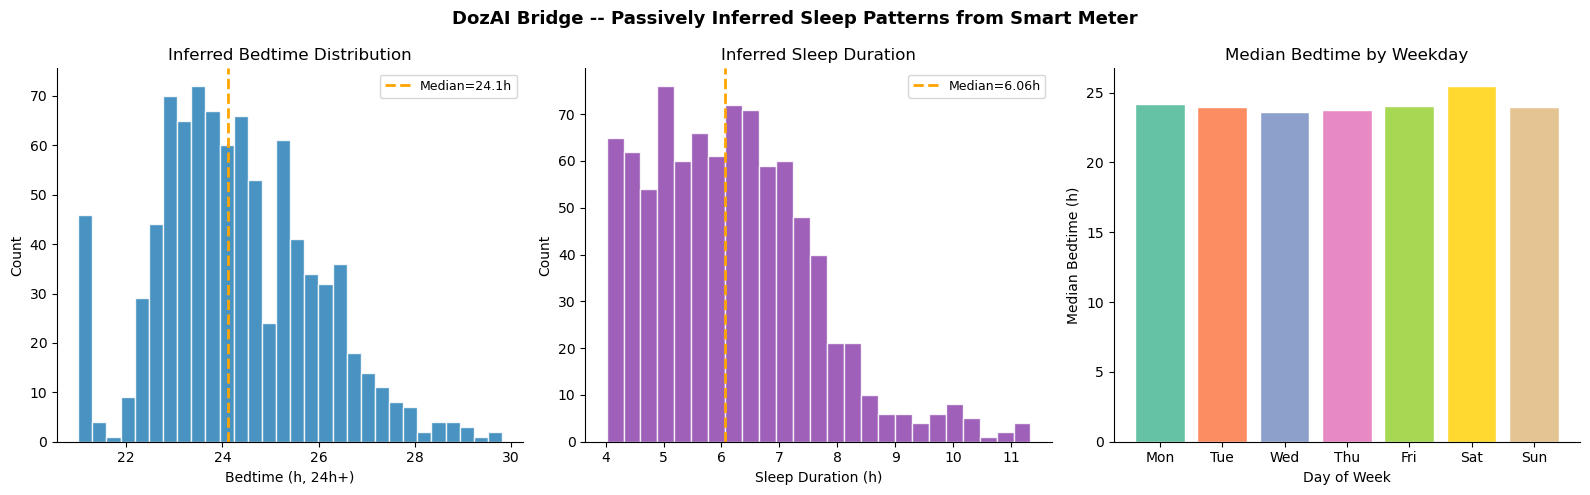

Saved figures/bridge.png


In [9]:
# ============================================================
# Cell 10 -- THE BRIDGE: passive bed/wake inference
# ============================================================
import math

print('Re-loading minute-level data for bridge analysis ...')
e_min_raw = pd.read_csv(
    DATA_TXT,
    sep=';', na_values='?', low_memory=False,
)
e_min_raw['datetime'] = pd.to_datetime(
    e_min_raw['Date'] + ' ' + e_min_raw['Time'],
    format='%d/%m/%Y %H:%M:%S',
    errors='coerce'
)
e_min_raw = e_min_raw.dropna(subset=['datetime']).drop(columns=['Date', 'Time'])
e_min_raw = e_min_raw.sort_values('datetime').set_index('datetime')
e_min_raw['Global_active_power'] = pd.to_numeric(e_min_raw['Global_active_power'], errors='coerce')
if 'Sub_metering_2' in e_min_raw.columns:
    e_min_raw['Sub_metering_2'] = pd.to_numeric(e_min_raw['Sub_metering_2'], errors='coerce')

# Resample to true 1-min index, interpolate small gaps
gap_load = e_min_raw['Global_active_power'].resample('1min').mean().interpolate(method='linear', limit=5)
# 15-min centered rolling median to bridge short appliance cycling spikes (e.g. refrigerator)
gap_smooth = gap_load.rolling(15, min_periods=1, center=True).median()

if 'Sub_metering_2' in e_min_raw.columns:
    sub2_raw = e_min_raw['Sub_metering_2'].resample('1min').mean().interpolate(method='linear', limit=5)
    sub2_kw  = sub2_raw * 60.0 / 1000.0   # Scale Wh/min to kW (Wh/min * 60 min/h / 1000 W/kW)
else:
    sub2_kw = pd.Series(0.0, index=gap_load.index)

# ---- Standby threshold (train-only, pre-2010) ----------------------------
THRESH_CUT = pd.Timestamp('2010-01-01')
_quiet_mask = (gap_load.index < THRESH_CUT) & (gap_load.index.hour.isin([3, 4]))
_quiet_vals = gap_load[_quiet_mask].dropna()
THR = float(max(0.03, 1.5 * float(_quiet_vals.median())))
print(f'Standby threshold THR = {THR:.4f} kW')

# ---- Day-by-day inference ------------------------------------------------
BRIDGE_START = pd.Timestamp('2007-01-01')
BRIDGE_END   = pd.Timestamp('2010-10-31')
all_days     = pd.date_range(BRIDGE_START, BRIDGE_END, freq='D')
print(f'Processing {len(all_days)} days ...')

nights          = []
days_total      = 0
days_miss_skip  = 0

for day in all_days:
    win_start = day + pd.Timedelta(hours=21)
    win_end   = day + pd.Timedelta(hours=34)   # next day 10:00
    seg       = gap_smooth[(gap_smooth.index >= win_start) & (gap_smooth.index < win_end)]
    days_total += 1

    if len(seg) == 0:
        continue

    # Skip if >30% missing
    exp_min      = 13 * 60
    missing_frac = seg.isna().sum() / exp_min
    if missing_frac > 0.30:
        days_miss_skip += 1
        continue

    # Gap search on <= THR
    seg_c   = seg.interpolate(method='linear', limit=10)
    is_q    = (seg_c <= THR).values
    seg_idx = seg_c.index

    best_len = 0
    best_s   = None
    best_e   = None
    cur_s    = None
    cur_len  = 0

    for i, q in enumerate(is_q):
        if q:
            if cur_s is None:
                cur_s = i
            cur_len += 1
        else:
            if cur_len > best_len:
                best_len = cur_len
                best_s   = cur_s
                best_e   = i - 1
            cur_s   = None
            cur_len = 0
    # trailing run
    if cur_len > best_len:
        best_len = cur_len
        best_s   = cur_s
        best_e   = len(is_q) - 1

    if best_len < 240 or best_s is None:
        continue

    bed_ts  = seg_idx[best_s - 1] if best_s > 0 else seg_idx[0]
    wake_ts = seg_idx[best_e + 1] if best_e + 1 < len(seg_idx) else seg_idx[-1]

    sleep_h = (wake_ts - bed_ts).total_seconds() / 3600.0
    if not (4.0 <= sleep_h <= 12.0):
        continue

    bed_h = float(bed_ts.hour + bed_ts.minute / 60.0)
    if bed_h < 12.0:
        bed_h += 24.0          # e.g. 01:00 -> 25.0 for chronotype continuity

    wake_h = float(wake_ts.hour + wake_ts.minute / 60.0)

    # Pre-bed noise: sub2 > 0.3 kW in 2 h before bedtime
    pb_start = bed_ts - pd.Timedelta(hours=2)
    pb_seg   = sub2_kw[(sub2_kw.index >= pb_start) & (sub2_kw.index < bed_ts)]
    noisy_prebed = float((pb_seg > 0.3).sum()) if len(pb_seg) > 0 else 0.0

    nights.append({
        'date':         day.date(),
        'bed_ts':       bed_ts,
        'wake_ts':      wake_ts,
        'bed_h':        bed_h,
        'wake_h':       wake_h,
        'sleep_h':      float(sleep_h),
        'dow':          int(day.dayofweek),
        'noisy_prebed': noisy_prebed,
    })

nightly_raw = pd.DataFrame(nights)
nightly_raw['date'] = pd.to_datetime(nightly_raw['date'])

cov_pct = 100.0 * len(nightly_raw) / max(days_total, 1)
print(f'Coverage   : {cov_pct:.1f}%  ({len(nightly_raw)} / {days_total} days)')
print(f'Miss-skipped: {days_miss_skip}')
print(f'Median sleep_h : {nightly_raw["sleep_h"].median():.2f} h')
print(f'Median bed_h   : {nightly_raw["bed_h"].median():.1f} h')

bridge_stats = {
    'coverage_pct':   float(cov_pct),
    'n_nights':       int(len(nightly_raw)),
    'median_sleep_h': float(nightly_raw['sleep_h'].median()),
    'median_bed_h':   float(nightly_raw['bed_h'].median()),
}

# ---- 3-panel figure ------------------------------------------------------
fig_br, ax_br = plt.subplots(1, 3, figsize=(16, 5))
fig_br.suptitle(
    'DozAI Bridge -- Passively Inferred Sleep Patterns from Smart Meter',
    fontsize=13, fontweight='bold'
)

ax = ax_br[0]
ax.hist(nightly_raw['bed_h'], bins=30, color='#2980b9', edgecolor='white', alpha=0.85)
ax.axvline(nightly_raw['bed_h'].median(), color='orange', lw=2, ls='--',
           label=f'Median={nightly_raw["bed_h"].median():.1f}h')
ax.set_title('Inferred Bedtime Distribution')
ax.set_xlabel('Bedtime (h, 24h+)')
ax.set_ylabel('Count')
ax.legend(fontsize=9)
sns.despine(ax=ax)

ax = ax_br[1]
ax.hist(nightly_raw['sleep_h'], bins=25, color='#8e44ad', edgecolor='white', alpha=0.85)
ax.axvline(nightly_raw['sleep_h'].median(), color='orange', lw=2, ls='--',
           label=f'Median={nightly_raw["sleep_h"].median():.2f}h')
ax.set_title('Inferred Sleep Duration')
ax.set_xlabel('Sleep Duration (h)')
ax.set_ylabel('Count')
ax.legend(fontsize=9)
sns.despine(ax=ax)

ax = ax_br[2]
dow_lbl = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
bed_dow = nightly_raw.groupby('dow')['bed_h'].median()
ax.bar(bed_dow.index, bed_dow.values,
       color=sns.color_palette('Set2', 7), edgecolor='white')
ax.set_xticks(range(7))
ax.set_xticklabels(dow_lbl)
ax.set_title('Median Bedtime by Weekday')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Median Bedtime (h)')
sns.despine(ax=ax)

plt.tight_layout()
fig_br.savefig('figures/bridge.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/bridge.png')


In [10]:
# ============================================================
# Cell 11 -- Nightly sleep layer: features + disclosed generator + models
# ============================================================

ndf = nightly_raw.copy().set_index('date').sort_index()

# ---- temp_at_bed: temp_out at 21:00 asof + 3.0 (twin constant) -----------
_ht = hourly[['temp_out']].copy()
_ht.index = pd.to_datetime(_ht.index)

def _t_at_21(date):
    ts = pd.Timestamp(date) + pd.Timedelta(hours=21)
    try:
        idx = _ht.index.asof(ts)
        v   = _ht.loc[idx, 'temp_out']
        return float(v) if not pd.isna(v) else float('nan')
    except Exception:
        return float('nan')

ndf['temp_at_bed'] = [_t_at_21(d) + 3.0 for d in ndf.index]

# ---- standby_w: 24h rolling min -> daily mean * 1000, shift(1) -----------
_daily_kw = hourly['kw'].resample('D').mean() * 1000.0   # Watts
ndf['standby_w'] = (
    _daily_kw.rolling(24, min_periods=1).min()
              .shift(1)
              .reindex(ndf.index)
)

# ---- AR(1) stress proxy --------------------------------------------------
STRESS_SEED = pd.Timestamp('2010-01-01')
stress_vals = []
prev_s = 5.0
for d in ndf.index:
    is_mon = pd.Timestamp(d).dayofweek == 0
    s = float(np.clip(
        0.55 * prev_s + float(RNG.normal(2.6, 1.3)) + (0.6 if is_mon else 0.0),
        1.0, 10.0
    ))
    stress_vals.append(s)
    prev_s = s
ndf['stress'] = stress_vals

# ---- Chronotype (train-only, pre-2010) -----------------------------------
CHRONO_CUT = pd.Timestamp('2010-01-01')
chrono = float(ndf[ndf.index < CHRONO_CUT]['bed_h'].median())
ndf['bed_dev'] = ndf['bed_h'] - chrono
print(f'Chronotype (median bed_h, pre-2010): {chrono:.2f} h')

# ---- DISCLOSED sleep quality generator -----------------------------------
# q = 72 - 9*bed_dev^2 - 1.8*(T-18.5)^2 - 0.5*clip(noisy,20)
#       - 2.7*clip(stress-5, 0+) + 2.0*(dow>=4) + N(0,3), clip 5-100
def _gen_q(bed_dev, temp_at_bed, noisy_prebed, stress, dow):
    q = (
        72.0
        - 9.0  * bed_dev**2
        - 1.8  * (temp_at_bed - 18.5)**2
        - 0.5  * min(float(noisy_prebed), 20.0)
        - 2.7  * max(float(stress) - 5.0, 0.0)
        + 2.0  * (1 if int(dow) >= 4 else 0)
        + float(RNG.normal(0.0, 3.0))
    )
    return float(np.clip(q, 5.0, 100.0))

ndf['q'] = [
    _gen_q(row['bed_dev'], row['temp_at_bed'],
           row['noisy_prebed'], row['stress'], row['dow'])
    for _, row in ndf.iterrows()
]

# ---- Lag features (shift BEFORE rolling) ---------------------------------
ndf['lag_q']      = ndf['q'].shift(1)
ndf['lag_stress'] = ndf['stress'].shift(1)
ndf['roll7_q']    = ndf['q'].shift(1).rolling(7, min_periods=3).mean()

# Cache
ndf.to_csv('data/nightly.csv')
print(f'Saved data/nightly.csv: {ndf.shape}')

# ---- Train/test split ----------------------------------------------------
SLP_TRAIN_CUT = pd.Timestamp('2010-06-01')
SF = ['bed_dev','temp_at_bed','noisy_prebed','stress',
      'lag_q','lag_stress','roll7_q','standby_w','dow']

ndf_cl = ndf.dropna(subset=SF + ['q'])
n_train_s = ndf_cl[ndf_cl.index < SLP_TRAIN_CUT]
n_test_s  = ndf_cl[ndf_cl.index >= SLP_TRAIN_CUT]
print(f'Sleep regression -- Train: {len(n_train_s)}, Test: {len(n_test_s)}')

Xtr_sl, ytr_sl = n_train_s[SF], n_train_s['q']
Xte_sl, yte_sl = n_test_s[SF],  n_test_s['q']

# Ridge
ridge_slp = make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=42))
ridge_slp.fit(Xtr_sl, ytr_sl)
yp_ridge = ridge_slp.predict(Xte_sl)
r_mae = float(mean_absolute_error(yte_sl, yp_ridge))
r_r2  = float(r2_score(yte_sl, yp_ridge))

# XGBoost regressor for sleep
sleep_xgb = XGBRegressor(
    n_estimators=500, learning_rate=0.04, max_depth=4,
    random_state=42, verbosity=0
)
sleep_xgb.fit(Xtr_sl, ytr_sl)
yp_xsl  = sleep_xgb.predict(Xte_sl)
x_mae   = float(mean_absolute_error(yte_sl, yp_xsl))
x_r2    = float(r2_score(yte_sl, yp_xsl))

print('\n=== Sleep Quality Regression ===')
print(f'{"Model":<20} {"MAE":>8} {"R2":>8}')
print('-' * 40)
print(f'{"Ridge":<20} {r_mae:>8.3f} {r_r2:>8.3f}')
print(f'{"XGBoost":<20} {x_mae:>8.3f} {x_r2:>8.3f}')

_slp_reg_res = {
    'Ridge_MAE': r_mae, 'Ridge_R2': r_r2,
    'XGB_MAE':   x_mae, 'XGB_R2':   x_r2,
}

Chronotype (median bed_h, pre-2010): 23.98 h
Saved data/nightly.csv: (888, 15)
Sleep regression -- Train: 797, Test: 88



=== Sleep Quality Regression ===
Model                     MAE       R2
----------------------------------------
Ridge                  16.404    0.187
XGBoost                 3.229    0.968


In [11]:
# ============================================================
# Cell 12 -- Digital TWIN config + MILP solver
# ============================================================

# ---- Twin config ---------------------------------------------------------
TWIN = {
    'tariff': {
        'off_peak': {'rate_rs': 5.0,
                     'hours': list(range(22, 24)) + list(range(0, 6))},
        'mid':      {'rate_rs': 6.5, 'hours': list(range(6, 18))},
        'peak':     {'rate_rs': 9.0, 'hours': list(range(18, 22))},
    },
    'appliances': {
        'dishwasher':   {'kw': 1.1, 'slots': 8,  'noisy': True},
        'washer':       {'kw': 0.6, 'slots': 10, 'noisy': True,  'deadline_h': 14},
        'dryer':        {'kw': 2.2, 'slots': 12, 'noisy': True},
        'water_heater': {'kw': 2.0, 'slots': 8,  'noisy': False},
        'ev_charger':   {'kw': 3.3, 'slots': 24, 'noisy': False, 'deadline_h': 6},
    },
    'thermal': {'G': 3.0, 'E': 3.0, 'T_opt': 18.5, 'T_min': 16.0},
}

with open('data/twin_config.json', 'w', encoding='utf-8') as _f:
    json.dump(TWIN, _f, indent=2)
print('Saved data/twin_config.json')

# ---- Slot tariff array ---------------------------------------------------
S  = 96
DT = 0.25
TARIFF = np.zeros(S)
for _t in range(S):
    _h = _t // 4
    if _h in TWIN['tariff']['off_peak']['hours']:
        TARIFF[_t] = TWIN['tariff']['off_peak']['rate_rs']
    elif _h in TWIN['tariff']['peak']['hours']:
        TARIFF[_t] = TWIN['tariff']['peak']['rate_rs']
    else:
        TARIFF[_t] = TWIN['tariff']['mid']['rate_rs']

# ---- MILP solver ---------------------------------------------------------
def solve_day(bed_h, T_out_bed, lam_noise=120, lam_temp=25, lam_peak=40):
    """
    Solve DozAI MILP for one day.
    bed_h     : bedtime in fractional hours (may exceed 24 for after-midnight)
    T_out_bed : outdoor temp at bedtime (deg C)
    Returns   : dict with starts, cost_rs, T_bed, hvac_kwh, status
               or None if infeasible
    """
    G, E, T_opt, T_min = (
        TWIN['thermal']['G'], TWIN['thermal']['E'],
        TWIN['thermal']['T_opt'], TWIN['thermal']['T_min'],
    )

    bed_slot  = int(round((bed_h % 24) * 4)) % S
    cool_sl   = [(bed_slot - 24 + i) % S for i in range(24)]  # 6-h pre-cool
    noisy_set = set((bed_slot + k) % S for k in range(-8, 9))

    prob = pulp.LpProblem('DozAI', pulp.LpMinimize)

    appl_names = list(TWIN['appliances'].keys())
    s_vars = {}   # binary start indicators
    u_vars = {}   # run indicators

    for nm, ap in TWIN['appliances'].items():
        dur  = ap['slots']
        sv   = [pulp.LpVariable(f's_{nm}_{t}', cat='Binary') for t in range(S)]
        uv   = [pulp.LpVariable(f'u_{nm}_{t}', cat='Binary') for t in range(S)]
        s_vars[nm] = sv
        u_vars[nm] = uv

        # Exactly one start
        prob += pulp.lpSum(sv) == 1, f'one_start_{nm}'

        # Deadline constraint
        if 'deadline_h' in ap:
            dl = int(ap['deadline_h'] * 4) % S
            for t in range(S):
                if t > max(0, dl - dur):
                    prob += sv[t] == 0, f'dl_{nm}_{t}'

        # Contiguous run: u[t] = sum of s[k] where (t-k) mod S < dur
        for t in range(S):
            run_expr = pulp.lpSum(sv[k] for k in range(S) if 0 <= (t - k) % S < dur)
            prob += uv[t] == run_expr, f'run_{nm}_{t}'

    # HVAC
    hv = [pulp.LpVariable(f'hv_{t}', lowBound=0, upBound=1.2) for t in range(S)]
    for t in range(S):
        if t not in cool_sl:
            prob += hv[t] == 0, f'hv0_{t}'

    hv_kwh = pulp.lpSum(hv[t] * DT for t in cool_sl)
    T_bed  = T_out_bed + G - E * hv_kwh

    dvar = pulp.LpVariable('dvar', lowBound=0)
    prob += dvar >= T_bed - T_opt,  'dv_u'
    prob += dvar >= T_opt - T_bed,  'dv_l'
    prob += T_bed >= T_min,         'T_min'

    # Cost
    cost_expr = pulp.lpSum(
        TARIFF[t] * ap['kw'] * DT * u_vars[nm][t]
        for nm, ap in TWIN['appliances'].items()
        for t in range(S)
    ) + pulp.lpSum(TARIFF[t] * hv[t] * DT for t in range(S))

    # Noise
    noise_expr = pulp.lpSum(
        DT * u_vars[nm][t]
        for nm, ap in TWIN['appliances'].items()
        if ap.get('noisy', False)
        for t in noisy_set
    )

    # Peak
    M = pulp.LpVariable('M', lowBound=0)
    for t in range(S):
        prob += M >= (
            pulp.lpSum(TWIN['appliances'][nm]['kw'] * u_vars[nm][t] for nm in appl_names)
            + hv[t]
        ), f'pk_{t}'

    prob += cost_expr + lam_noise * noise_expr + lam_temp * dvar + lam_peak * M

    prob.solve(pulp.PULP_CBC_CMD(msg=0))

    if prob.status not in (1,):   # 1 = Optimal
        # Try to extract anyway if solver found a feasible point
        pass

    starts = {}
    for nm in appl_names:
        for t in range(S):
            v = pulp.value(s_vars[nm][t])
            if v is not None and v > 0.5:
                starts[nm] = t
                break
        if nm not in starts:
            starts[nm] = 0

    hv_kwh_val = float(sum(
        (pulp.value(hv[t]) or 0.0) * DT for t in cool_sl
    ))
    T_bed_val  = float(T_out_bed + G - E * hv_kwh_val)

    # Actual monetary cost
    cost_val = 0.0
    for nm, ap in TWIN['appliances'].items():
        dur = ap['slots']
        st  = starts[nm]
        for i in range(dur):
            t_r = (st + i) % S
            cost_val += TARIFF[t_r] * ap['kw'] * DT
    for t in range(S):
        hv_v = pulp.value(hv[t])
        if hv_v:
            cost_val += TARIFF[t] * hv_v * DT

    return {
        'starts':   starts,
        'cost_rs':  float(cost_val),
        'T_bed':    T_bed_val,
        'hvac_kwh': hv_kwh_val,
        'status':   pulp.LpStatus[prob.status],
    }

# ---- Demo ----------------------------------------------------------------
print('Demo: solve_day(bed_h=23.2, T_out_bed=27.0) ...')
demo = solve_day(23.2, 27.0)
if demo:
    print(f'Status   : {demo["status"]}')
    print(f'Cost     : Rs {demo["cost_rs"]:.2f}')
    print(f'T_bed    : {demo["T_bed"]:.1f} deg C')
    print(f'HVAC kWh : {demo["hvac_kwh"]:.3f}')
    print('Appliance schedule (slot -> HH:MM):')
    for nm, sl in demo['starts'].items():
        hh, mm = divmod(sl * 15, 60)
        print(f'  {nm:<15}: slot {sl:>2} = {hh:02d}:{mm:02d}')

Saved data/twin_config.json
Demo: solve_day(bed_h=23.2, T_out_bed=27.0) ...


Status   : Optimal
Cost     : Rs 212.20
T_bed    : 18.5 deg C
HVAC kWh : 3.833
Appliance schedule (slot -> HH:MM):
  dishwasher     : slot 58 = 14:30
  washer         : slot 34 = 08:30
  dryer          : slot 53 = 13:15
  water_heater   : slot 88 = 22:00
  ev_charger     : slot  0 = 00:00


3-way replay on 88 test nights ...



=== 3-Way Replay (medians, 88 nights) ===
Arm             MedCost     MedQ    DeltaCost     DeltaQ
----------------------------------------------------------
as_run           247.60     10.3         0.00        0.0
cheapest         182.65     10.2       -64.95       -0.1
co_opt           192.53     42.9       -55.07       32.5

Estimated annual saving (co_opt vs as_run): Rs 20099

Pareto sweep (13 steps) on hottest night (T_out=28.6 degC) ...


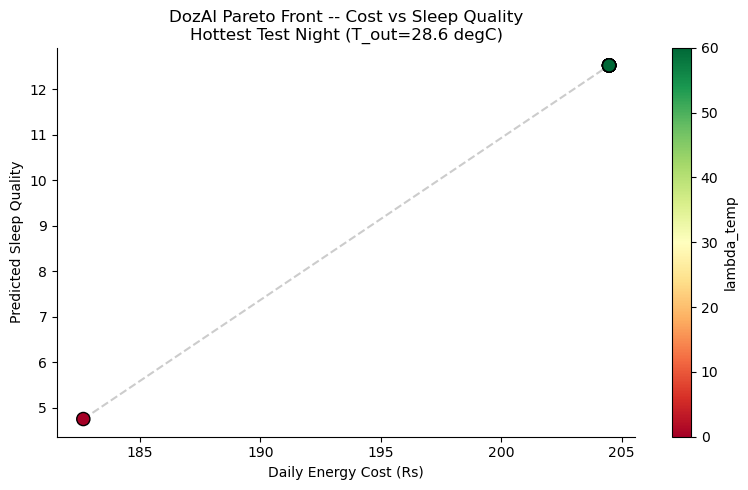

Saved figures/pareto.png

Sensitivity: lam_noise and lam_temp +/-50% ...


  lam_noise: 50%: changed=['none']; 150%: changed=['none']
  lam_temp: 50%: changed=['none']; 150%: changed=['none']


In [12]:
# ============================================================
# Cell 13 -- 3-way replay + Pareto + sensitivity
# ============================================================

# Fixed habitual evening starts (slot numbers, 1 slot = 15 min)
habitual = {
    'dishwasher':   int(20.0 * 4),   # 20:00
    'washer':       int(8.0  * 4),   # 08:00 (morning wash)
    'dryer':        int(17.5 * 4),   # 17:30
    'water_heater': int(19.5 * 4),   # 19:30
    'ev_charger':   int(20.0 * 4),   # 20:00
}

def _compute_cost(starts, hvac_kwh=0.0):
    """Monetary cost of appliance schedule + HVAC electricity consumption."""
    total = 0.0
    for nm, ap in TWIN['appliances'].items():
        st = starts.get(nm, 0)
        for i in range(ap['slots']):
            t = (st + i) % S
            total += TARIFF[t] * ap['kw'] * DT
    total += TWIN['tariff']['off_peak']['rate_rs'] * hvac_kwh
    return float(total)

def score_schedule(starts, bed_h, T_bed, stress_v, lag_q_v,
                   lag_s_v, r7q_v, sw_v, dow_v):
    """
    Two-channel design: optimizer channels -> appliance starts and bedroom T_bed.
    Behavioral channels (stress, lags) are fixed per day.
    """
    # Noise from proposed starts
    bed_mod  = bed_h % 24
    bed_sl   = int(round(bed_mod * 4)) % S
    noisy_set2 = set((bed_sl + k) % S for k in range(-8, 9))
    np_new = 0.0
    for nm, ap in TWIN['appliances'].items():
        if ap.get('noisy', False):
            st = starts.get(nm, 0)
            for i in range(ap['slots']):
                if (st + i) % S in noisy_set2:
                    np_new += DT * 60.0   # minutes

    bd_dev = bed_h - chrono
    feats  = pd.DataFrame([{
        'bed_dev':      bd_dev,
        'temp_at_bed':  T_bed,
        'noisy_prebed': np_new,
        'stress':       stress_v,
        'lag_q':        lag_q_v,
        'lag_stress':   lag_s_v,
        'roll7_q':      r7q_v,
        'standby_w':    sw_v,
        'dow':          dow_v,
    }])
    return float(sleep_xgb.predict(feats)[0])

# ---- Replay on test nights -----------------------------------------------
REPLAY_START = pd.Timestamp('2010-06-01')
test_nights  = ndf_cl[ndf_cl.index >= REPLAY_START].head(150)
print(f'3-way replay on {len(test_nights)} test nights ...')

arms = {k: [] for k in ['as_run','cheapest','co_opt']}

for day_date, row in test_nights.iterrows():
    bh   = float(row['bed_h'])
    Tout = float(row['temp_at_bed']) - 3.0
    sv   = float(row['stress'])
    lq   = float(row['lag_q'])      if not pd.isna(row['lag_q'])      else 70.0
    ls   = float(row['lag_stress']) if not pd.isna(row['lag_stress']) else 5.0
    r7   = float(row['roll7_q'])    if not pd.isna(row['roll7_q'])    else 70.0
    sw   = float(row['standby_w'])  if not pd.isna(row['standby_w'])  else 50.0
    dw   = int(row['dow'])

    # 1. as_run: habitual starts, unmanaged bedroom temp
    T_as_run = Tout + TWIN['thermal']['G']
    c_as_run = _compute_cost(habitual, hvac_kwh=0.0)
    q_as_run = score_schedule(habitual, bh, T_as_run, sv, lq, ls, r7, sw, dw)
    arms['as_run'].append({'cost': c_as_run, 'q': q_as_run})

    # 2. cheapest: lam_noise=0, lam_temp=0 -> no cooling
    cr = solve_day(bh, Tout, lam_noise=0, lam_temp=0)
    ch_st = cr['starts'] if cr else habitual
    ch_hvac = cr['hvac_kwh'] if cr else 0.0
    ch_tbed = cr['T_bed'] if cr else T_as_run
    c_ch = _compute_cost(ch_st, hvac_kwh=ch_hvac)
    q_ch = score_schedule(ch_st, bh, ch_tbed, sv, lq, ls, r7, sw, dw)
    arms['cheapest'].append({'cost': c_ch, 'q': q_ch})

    # 3. co_opt: balanced cost + sleep protection with pre-cooling
    or_ = solve_day(bh, Tout)
    co_st = or_['starts'] if or_ else habitual
    co_hvac = or_['hvac_kwh'] if or_ else 0.0
    co_tbed = or_['T_bed'] if or_ else T_as_run
    c_co = _compute_cost(co_st, hvac_kwh=co_hvac)
    q_co = score_schedule(co_st, bh, co_tbed, sv, lq, ls, r7, sw, dw)
    arms['co_opt'].append({'cost': c_co, 'q': q_co})

def _med(lst, key):
    return float(np.median([x[key] for x in lst]))

ar_c = _med(arms['as_run'], 'cost')
ar_q = _med(arms['as_run'], 'q')
ch_c = _med(arms['cheapest'], 'cost')
ch_q = _med(arms['cheapest'], 'q')
co_c = _med(arms['co_opt'], 'cost')
co_q = _med(arms['co_opt'], 'q')

replay_table = [
    {'arm':'as_run',   'median_cost':ar_c, 'median_q':ar_q, 'delta_cost':0.0,       'delta_q':0.0},
    {'arm':'cheapest', 'median_cost':ch_c, 'median_q':ch_q, 'delta_cost':ch_c-ar_c, 'delta_q':ch_q-ar_q},
    {'arm':'co_opt',   'median_cost':co_c, 'median_q':co_q, 'delta_cost':co_c-ar_c, 'delta_q':co_q-ar_q},
]

print(f'\n=== 3-Way Replay (medians, {len(test_nights)} nights) ===')
print(f'{"Arm":<12} {"MedCost":>10} {"MedQ":>8} {"DeltaCost":>12} {"DeltaQ":>10}')
print('-' * 58)
for rr in replay_table:
    print(f'{rr["arm"]:<12} {rr["median_cost"]:>10.2f} {rr["median_q"]:>8.1f} '
          f'{rr["delta_cost"]:>12.2f} {rr["delta_q"]:>10.1f}')

annual_saving = float((ar_c - co_c) * 365)
print(f'\nEstimated annual saving (co_opt vs as_run): Rs {annual_saving:.0f}')

# ---- Pareto sweep --------------------------------------------------------
hot_idx = test_nights['temp_at_bed'].idxmax()
hot_row = test_nights.loc[hot_idx]
hot_bh  = float(hot_row['bed_h'])
hot_T   = float(hot_row['temp_at_bed']) - 3.0
hot_sv  = float(hot_row['stress'])
hot_lq  = float(hot_row['lag_q'])      if not pd.isna(hot_row['lag_q'])      else 70.0
hot_ls  = float(hot_row['lag_stress']) if not pd.isna(hot_row['lag_stress']) else 5.0
hot_r7  = float(hot_row['roll7_q'])    if not pd.isna(hot_row['roll7_q'])    else 70.0
hot_sw  = float(hot_row['standby_w'])  if not pd.isna(hot_row['standby_w'])  else 50.0
hot_dw  = int(hot_row['dow'])

lam_temps = np.linspace(0, 60, 13)
par_cost, par_q = [], []
print(f'\nPareto sweep ({len(lam_temps)} steps) on hottest night (T_out={hot_T:.1f} degC) ...')
for lt in lam_temps:
    pr = solve_day(hot_bh, hot_T, lam_noise=120, lam_temp=float(lt))
    if pr:
        pc = _compute_cost(pr['starts'], hvac_kwh=pr['hvac_kwh'])
        pq = score_schedule(pr['starts'], hot_bh, pr['T_bed'], hot_sv,
                            hot_lq, hot_ls, hot_r7, hot_sw, hot_dw)
        par_cost.append(pc)
        par_q.append(pq)
    else:
        par_cost.append(float('nan'))
        par_q.append(float('nan'))

fig_pa, ax_pa = plt.subplots(figsize=(8, 5))
sc_pa = ax_pa.scatter(par_cost, par_q, c=lam_temps, cmap='RdYlGn', s=90, edgecolors='k', zorder=5)
ax_pa.plot(par_cost, par_q, '--', alpha=0.4, color='gray')
plt.colorbar(sc_pa, ax=ax_pa, label='lambda_temp')
ax_pa.set_xlabel('Daily Energy Cost (Rs)')
ax_pa.set_ylabel('Predicted Sleep Quality')
ax_pa.set_title(f'DozAI Pareto Front -- Cost vs Sleep Quality\nHottest Test Night (T_out={hot_T:.1f} degC)')
sns.despine(ax=ax_pa)
plt.tight_layout()
fig_pa.savefig('figures/pareto.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/pareto.png')

# ---- Sensitivity ---------------------------------------------------------
print('\nSensitivity: lam_noise and lam_temp +/-50% ...')
base_res = solve_day(hot_bh, hot_T)
base_st  = base_res['starts'] if base_res else habitual

sensitivity = {}
for param, base_val in [('lam_noise', 120), ('lam_temp', 25)]:
    diffs = []
    for fac in [0.5, 1.5]:
        kw = {'lam_noise': 120, 'lam_temp': 25, param: base_val * fac}
        sr = solve_day(hot_bh, hot_T, **kw)
        if sr:
            changed = [nm for nm in base_st
                       if abs(sr['starts'].get(nm,0) - base_st.get(nm,0)) >= 4]
            diffs.append(f'{int(fac*100)}%: changed={changed or ["none"]}')
    sensitivity[param] = '; '.join(diffs)

for k, v in sensitivity.items():
    print(f'  {k}: {v}')


Computing SHAP for energy model (Oct 2010) ...


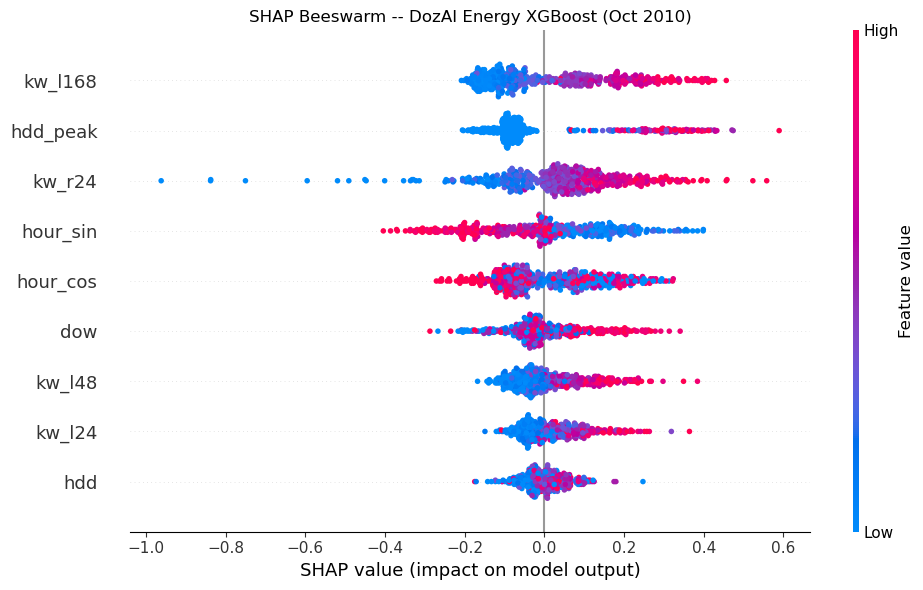

Saved figures/shap_energy.png
Computing SHAP for sleep model (test set) ...


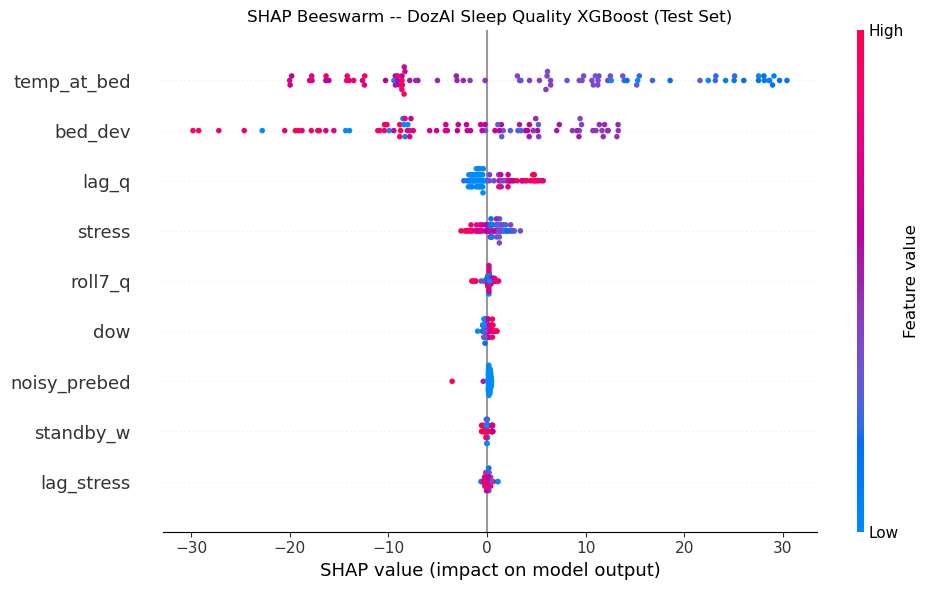

Saved figures/shap_sleep.png
Models saved to models/
Saved models/results.json

ALL DONE -- DozAI artifacts ready

Next step: python make_report.py

Submit 4 files:
  1. sleepai.ipynb
  2. requirements.txt
  3. make_report.py
  4. Akash_Kumar_DozAI_ProjectReport.docx


In [13]:
# ============================================================
# Cell 14 -- SHAP + save models + results.json
# ============================================================

# ---- SHAP: energy XGBoost (Oct 2010 sample) ------------------------------
print('Computing SHAP for energy model (Oct 2010) ...')
oct_mask  = (h.index >= pd.Timestamp('2010-10-01')) & (h.index < pd.Timestamp('2010-11-01'))
X_shap_e  = h[oct_mask][FEATURE_COLS].dropna()
if len(X_shap_e) > 500:
    X_shap_e = X_shap_e.sample(500, random_state=42)

exp_e      = shap.TreeExplainer(xgb_e)
sv_e       = exp_e.shap_values(X_shap_e)

fig_se = plt.figure(figsize=(10, 6))
shap.summary_plot(sv_e, X_shap_e, plot_type='dot', show=False, max_display=9, plot_size=None)
plt.title('SHAP Beeswarm -- DozAI Energy XGBoost (Oct 2010)', fontsize=12)
plt.tight_layout()
plt.savefig('figures/shap_energy.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/shap_energy.png')

# ---- SHAP: sleep XGBoost (test rows) -------------------------------------
print('Computing SHAP for sleep model (test set) ...')
X_shap_s = Xte_sl.copy()
if len(X_shap_s) > 300:
    X_shap_s = X_shap_s.sample(300, random_state=42)

exp_s = shap.TreeExplainer(sleep_xgb)
sv_s  = exp_s.shap_values(X_shap_s)

fig_ss = plt.figure(figsize=(10, 6))
shap.summary_plot(sv_s, X_shap_s, plot_type='dot', show=False, max_display=9, plot_size=None)
plt.title('SHAP Beeswarm -- DozAI Sleep Quality XGBoost (Test Set)', fontsize=12)
plt.tight_layout()
plt.savefig('figures/shap_sleep.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/shap_sleep.png')

# ---- Dump models ---------------------------------------------------------
joblib.dump(xgb_e,     'models/xgb_energy.joblib')
joblib.dump(sleep_xgb, 'models/sleep_xgb.joblib')
print('Models saved to models/')

# ---- Save results.json ---------------------------------------------------
def _to_py(v):
    if isinstance(v, (np.floating, np.integer)):
        return float(v)
    if isinstance(v, np.ndarray):
        return v.tolist()
    return v

results_json = {
    'forecast_table': [
        {k: _to_py(v) for k, v in row.items()}
        for row in forecast_table
    ],
    'xgb_vs_seasonal_naive_improvement': {
        k: _to_py(v) for k, v in xgb_vs_sn.items()
    },
    'sleep_regression':  {k: _to_py(v) for k, v in _slp_reg_res.items()},
    'sleep_classifier':  {k: _to_py(v) for k, v in _clf_res.items()},
    'anomaly_stats':     {k: _to_py(v) for k, v in anomaly_stats.items()},
    'bridge_stats':      {k: _to_py(v) for k, v in bridge_stats.items()},
    'replay_table':      [
        {k: _to_py(v) for k, v in r.items()} for r in replay_table
    ],
    'n_replay_nights':   int(len(test_nights)),
    'annual_saving_inr': float(annual_saving),
    'sensitivity':       sensitivity,
    'pareto': {
        'lam_temp_vals': [float(x) for x in lam_temps],
        'costs':         [float(x) for x in par_cost if not (isinstance(x, float) and x != x)],
        'qualities':     [float(x) for x in par_q    if not (isinstance(x, float) and x != x)],
    },
}

with open('models/results.json', 'w', encoding='utf-8') as f:
    json.dump(results_json, f, indent=2)
print('Saved models/results.json')

# ---- Done ----------------------------------------------------------------
print()
print('=' * 62)
print('ALL DONE -- DozAI artifacts ready')
print('=' * 62)
print()
print('Next step: python make_report.py')
print()
print('Submit 4 files:')
print('  1. sleepai.ipynb')
print('  2. requirements.txt')
print('  3. make_report.py')
print('  4. Akash_Kumar_DozAI_ProjectReport.docx')
